# Can gradients make better signal generators? — a follow-up to the investigation

*A follow-up to [the investigation](rapid_lightning_investigation.ipynb), on the same 16 datasets, folds and tuned baselines. Every number below is produced by [`benchmarks/gradgen_vs_gp.py`](../../benchmarks/gradgen_vs_gp.py), with defaults chosen on separate data by [`benchmarks/gradgen_dev.py`](../../benchmarks/gradgen_dev.py); nothing is hand-entered. October 2026.*

**The question.** Rapid Lightning v3 *evolves* its signal generators with genetic programming. Gradients beat evolution at fitting continuous models almost everywhere else. So what if the generators were *trained* instead: by gradient descent or other numerical methods, with or without the head-aware scheme?

**Short answer.** Yes: gradients make better generators than evolution does. But they don't rescue the method, and once gradients are available, the "head-aware" part stops mattering.

- **Better than GP.** Tuning v3's own numbers by gradient improves it on all 16 datasets (+0.016 AUC). Replacing GP outright with a jointly trained small MLP (same 24/20 generators, same logistic head) improves it by **+0.030 AUC on 13 of 16 datasets** (p = 0.003), and trains about 100× faster.
- **Still not better than tuned GBDTs.** It is level with the tuned GBDT stack on the 10 small datasets, where plain logistic regression also beats that stack on 6. On the 6 large ones it is still about 0.04 behind, about as far as GP. Across all 16 its average rank ties the GBDT stack's (3.50 vs 3.56), with a mean gap of −0.016 that is not significant (p = 0.21).
- **In the GBDT stack it adds +0.006 AUC** (p = 0.002; helps on 11 datasets, hurts on none). That is three times v1's +0.002 and the largest complementary signal measured in this project. But plain logistic regression adds +0.005 by itself, so most of it is smooth structure that trees approximate poorly, not anything specific to signal generators. It is also a small-data effect: +0.010 on small datasets, +0.001 on large.
- **Head-aware training stops helping once there are gradients.** Training the generators jointly beats growing them one at a time against the head's residual (+0.016, p = 0.002), and head-aware initialization adds nothing to joint training. Even *random search* over ridge units, scored by the head-aware objective, beats GP's evolution of it (+0.020, p = 0.04).
- **Has it been tried?** Yes, for about 35 years, as Cascade-Correlation, constructive networks and their descendants (§2).

## 1 · From evolved generators to trained ones

v3's model is a logistic head over K generators,

$$p(y{=}1\mid x) \;=\; \sigma\Big(c + \textstyle\sum_k v_k\, g_k(x)\Big),$$

where GP evolves each $g_k$ (an expression tree over `+ − × min max < …`) to maximize the head-aware fitness $\mathrm{corr}(g_k \perp \text{pool},\, R)^2$. Here $R = y - p$ is the current head's residual and "⟂ pool" means orthogonalized against the generators already chosen. Individually the generators are near-chance; through the head they classify.

To train a generator by gradient, it has to be differentiable in its parameters. The simplest such generator, and one that keeps the compiled artifact branchless, is a **ridge unit** $g_k(x) = \tanh(w_k\!\cdot\! x + b_k)$. Then the model is $\sigma(c + \sum_k v_k \tanh(w_k\!\cdot\! x + b_k))$, which is **a neural network with one hidden layer of K units.** Each way of training it maps onto something well known:

| how the generators are made | what that is |
|---|---|
| one at a time, each by gradient ascent on the head-aware objective, then frozen; head refit | Cascade-Correlation (Fahlman & Lebiere, 1990) without the cascade connections, i.e. a *constructive* network (Kwok & Yeung, 1997) |
| all at once, together with the head, on the log-loss | an ordinary small MLP |
| one at a time, then everything fine-tuned jointly | GrowNet's "corrective step" (Badirli et al., 2020) |
| one at a time, each picked from random candidates by the head-aware objective | Stochastic Configuration Networks (Wang & Li, 2017) |
| GP's trees kept, their numbers fitted by gradient | GP with gradient-based parameter fitting (Kommenda et al., 2020) |

A signal generator, individually weak but jointly useful through a linear readout, is exactly what a hidden unit is. **So replacing GP with gradients turns Rapid Lightning into a small neural network.** Whether that beats the GP ensemble or tuned GBDTs is an empirical question.

## 2 · Has it been tried? Yes — for about 35 years, under other names

| idea | prior art |
|---|---|
| Add hidden units one at a time. Train each candidate by gradient ascent to maximize its correlation (covariance) with the network's residual error, from a pool of random starts; freeze it; retrain the output layer | **Cascade-Correlation**: Fahlman & Lebiere, *Advances in NeurIPS 2* (1990) |
| Objective functions for training a new hidden unit against the residual, including the squared inner product with the residual over the unit's norm (v3's fitness, up to centering), with a universal-approximation guarantee for the greedy growth | **Kwok & Yeung**, *IEEE Trans. Neural Networks* 8 (1997), [doi:10.1109/72.623214](https://doi.org/10.1109/72.623214) |
| Fit a sequence of ridge functions, each to the previous residual | **Projection pursuit regression**: Friedman & Stuetzle, *JASA* 76 (1981) |
| Draw candidate hidden units at random, keep the one that best satisfies a residual-inner-product criterion, solve the output weights by least squares | **Stochastic Configuration Networks**: Wang & Li, *IEEE Trans. Cybernetics* 47 (2017), [arXiv:1702.03180](https://arxiv.org/abs/1702.03180) |
| Choose each new rule by the angle between the loss gradient and the rule's output *projected orthogonally to the rules already chosen* (v3's "⟂ pool") | **Orthogonal Gradient Boosting**: Yang, Le Bodic, Kamp & Boley, *AISTATS* (2024), [PMLR 238](https://proceedings.mlr.press/v238/yang24b.html) |
| Gradient boosting with shallow neural nets as weak learners, plus a fully corrective step | **GrowNet**: Badirli et al. (2020), [arXiv:2002.07971](https://arxiv.org/abs/2002.07971) |
| GP for model structure; numeric parameters fitted by gradient-based nonlinear least squares | **Kommenda, Burlacu, Kronberger & Affenzeller**, *Genetic Programming and Evolvable Machines* 21 (2020), [doi:10.1007/s10710-019-09371-3](https://doi.org/10.1007/s10710-019-09371-3) |

What is specific to Rapid Lightning is using *GP* as the search method for the head-aware objective and compiling the result to straight-line C. Swap that search for gradients and the method lands in the constructive-network literature.

## 3 · What we ran

The protocol is the investigation's: 16 OpenML datasets and repeated stratified CV (5×3 folds on small sets, 5×2 on large). Each training fold is split 70% fit / 15% early-stopping / 15% blending. The baseline is the same tuned (early-stopped, regularized) XGBoost + LightGBM + HistGB stack, with the same leakage-free stacker. Every comparison below is paired on identical folds.

| key | how the K generators are made | K |
|---|---|---|
| `v3` | GP, head-aware fitness (re-run, for pairing) | 2 per member: 24 small / 20 large |
| `v1` | GP, members as predictors (re-run, for pairing) | — |
| `v3t` | `v3`'s evolved trees, then **every number tuned by gradient**: each constant, a weight on every input leaf, a temperature on every `<` (relaxed to a sigmoid). Tuned jointly with the head by L-BFGS on log-loss, early-stopped | as v3 |
| `hac` | head-aware, one ridge unit at a time, each trained by **L-BFGS on v3's exact objective** corr(g ⟂ pool, R)², best of 6 starts, head refit after each; how many to keep is chosen on the early-stopping split | ≤ 24 / 20 |
| `ha` | the same, scored by the head's **exact Newton gain** (§3.1) | ≤ 24 / 20 |
| `haj` | `ha`, then all units and the head **fine-tuned jointly** on log-loss | ≤ 24 / 20 |
| `jt` | all units and the head **trained jointly from scratch** (a 1-hidden-layer MLP), early-stopped | 24 / 20 |
| `rnd` | head-aware, each unit **picked from 256 random candidates**: no gradients, no evolution | ≤ 24 / 20 |
| `lr` | logistic regression on the raw features: the linear control | — |

**Same budget, same data.** The generator count matches v3's head width (each v3 member is two trees). The head sees only the generators, as in v3. Every gradient method gets exactly the GBDTs' data: it fits on the 70% and early-stops / model-selects on the 15% early-stopping split. (v3 and v1 use only the 70%, as before; they have no early-stopping knob.) Gradients are analytic, in NumPy + SciPy only ([`rapidlightning/gradgen.py`](../../rapidlightning/gradgen.py), gradient-checked in [`tests/test_gradgen.py`](../../tests/test_gradgen.py)).

**Defaults chosen on other data.** Every knob (activation, regularization, early-stopping patience, direct input→head links, relaxation temperature) was picked on **14 separate OpenML datasets** by [`benchmarks/gradgen_dev.py`](../../benchmarks/gradgen_dev.py) and frozen before the benchmark ran. The 16 benchmark sets were never used for tuning. Along the way the dev runs showed that a 128-unit MLP is *worse* than a 24-unit one, so width is not what limits these models.

**Statistics.** Fold-level p-values (what the investigation reported) overstate significance, because CV folds share training data. The headline tests here are the ones recommended for comparing classifiers across datasets (Demšar, *JMLR* 2006): a Wilcoxon signed-rank test over the 16 per-dataset means, and Friedman average ranks with the Nemenyi critical difference.

### 3.1 · A snag on the way: v3's objective is ill-posed for gradient ascent

v3's fitness corr(g ⟂ pool, R)² is **scale-invariant**: shrink a generator's output and its correlation does not change. GP never notices, because its search is discrete. Gradient ascent does. A tanh unit can shrink its weights into the linear regime, where its output has tiny variance, at no cost in fitness, and a weight penalty actively *pushes* it there. Once a unit is linear, maximizing its correlation with the residual is plain least squares on the residual. With many features per row, that overfits by picking near-null directions of the data. v3's head then *standardizes* each generator, amplifying those tiny-variance units back up, and a joint fine-tune's weight decay crushes them to a constant. A smoke run of `haj` on sonar (60 collinear features, 116 training rows) produced exactly-constant predictions (AUC = 0.500) on 6 of 15 folds.

The fix is to score a generator by what it is actually worth to the head: the **exact gain of adding it to the L2-regularized logistic head** (one Newton step),

$$\text{gain}(u) \;=\; \frac{(u\cdot R)^2}{\lVert u\rVert^2 + \lambda_h}, \qquad \lambda_h = \frac{1}{C\cdot\overline{p(1-p)}},$$

with $u$ the candidate orthogonalized against the pool. This is the $G^2/(H+\lambda)$ form of XGBoost's split gain. Letting $\lambda_h \to 0$ recovers v3's corr², and a tiny-variance unit now scores ≈ 0. The head then works on raw generator outputs (tanh units are already bounded), so its own L2 penalty applies to them. The benchmark runs both objectives: `hac` (v3's) and `ha` (Newton).

The problem surfaced on a benchmark dataset, but as a correctness bug (constant predictions), not through tuning. The fix was validated and re-selected on **five extra high-dimensional dev datasets**, never on sonar, and those smoke-run results were discarded. Here is the same failure on fresh synthetic data:

In [1]:
import json, os, sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.width", 200)

# repo root: walk up until benchmarks/ is found (runs from the repo root or notebooks/methods)
root = os.path.abspath(".")
while not os.path.isdir(os.path.join(root, "benchmarks")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)
sys.path.insert(0, root)

In [2]:
# The degeneracy on fresh synthetic data (not a benchmark set): 60 strongly collinear
# "spectral bands" per row (like sonar), 120 rows to fit on, 30 to early-stop on.
import warnings; warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from rapidlightning.gradgen import RidgeHeadClassifier, _act

rng = np.random.default_rng(3)
t = np.linspace(0, 1, 60)
basis = np.exp(-((t[None, :] - np.linspace(0.05, 0.95, 6)[:, None]) ** 2) / (2 * 0.08 ** 2))
A = rng.normal(size=(2200, 6))
X = A @ basis + 0.05 * rng.normal(size=(2200, 60))
y = (rng.random(2200) < 1 / (1 + np.exp(-(1.5 * A[:, 0] * A[:, 1] - A[:, 2] + 0.8 * np.abs(A[:, 3]) - 0.6)))).astype(int)
X = ((X - X.mean(0)) / X.std(0)).astype(np.float32)
ev = np.linalg.eigvalsh(np.cov(X.T))
print(f"feature covariance eigenvalues: largest {ev.max():.1f}, median {np.median(ev):.4f}  (many near-null directions)\n")
for objective, alpha in (("corr", 10.0), ("newton", 30.0)):
    for method in ("headaware", "headaware+joint"):
        r = []
        for seed in range(3):
            Xf, Xr, yf, yr = train_test_split(X, y, train_size=120, random_state=seed, stratify=y)
            Xv, Xte, yv, yte = train_test_split(Xr, yr, train_size=30, random_state=seed, stratify=yr)
            m = RidgeHeadClassifier(n_units=24, method=method, objective=objective, alpha_unit=alpha,
                                    alpha_joint=3.0, seed=1).fit(Xf, yf, Xv, yv)
            H = _act(Xf.astype(float) @ m.W_.T + m.b_, "tanh")
            r.append((roc_auc_score(yte, m.decision_function(Xte)), np.median(H.std(0)), np.abs(m.v_).max()))
        r = np.array(r)
        print(f"{objective:<7} {method:<16} test AUC {np.round(r[:, 0], 3)}   median generator std {np.round(r[:, 1], 3)}"
              f"   largest head weight {np.round(r[:, 2], 1)}")

feature covariance eigenvalues: largest 16.3, median 0.0033  (many near-null directions)



corr    headaware        test AUC [0.53  0.513 0.583]   median generator std [0.01  0.555 0.014]   largest head weight [319.1   1.9 198.2]


corr    headaware+joint  test AUC [0.492 0.517 0.455]   median generator std [0.    0.665 0.   ]   largest head weight [0.3 1.2 0. ]


newton  headaware        test AUC [0.651 0.674 0.609]   median generator std [0.402 0.397 0.406]   largest head weight [1.6 2.1 1.5]


newton  headaware+joint  test AUC [0.651 0.674 0.603]   median generator std [0.402 0.397 0.591]   largest head weight [1.6 2.1 0.9]


With collinear features and few rows, gradient ascent on v3's objective finds generators whose output barely varies and that need head weights in the hundreds. Test AUC sits near chance, and the joint fine-tune collapses to a constant. The Newton gain keeps the generators well-behaved (healthy variance, small head weights) and they generalize. GP's discrete search is protected from this by construction; any continuous optimizer of v3's objective is not.

## 4 · Results

### 4.1 · Solo: each model on its own

In [3]:
from benchmarks.gradgen_stats import load, LABELS, xds_wilcoxon, wins, friedman_ranks
fmt_p = lambda p: "<0.0001" if p < 1e-4 else f"{p:.4f}"

rows = sorted(load(os.environ.get("GG_SUMMARY", os.path.join(root, "benchmarks/results/gradgen_vs_gp.jsonl"))),
              key=lambda r: r["n"])
M = ["lr", "v1", "v3", "v3t", "hac", "ha", "jt", "haj", "rnd"]
mean = pd.DataFrame([{k: r["mean"][k] for k in ["g"] + M} for r in rows], index=[r["name"] for r in rows])
stackd = pd.DataFrame([{m: r["d_stack"][m] for m in M} for r in rows], index=mean.index)
print(f"{len(rows)} datasets | {sum(r['folds'] for r in rows)} CV folds, every model paired on every fold")

16 datasets | 210 CV folds, every model paired on every fold


In [4]:
ranks, p_friedman, cd = friedman_ranks(rows, ["g"] + M)
tab = []
for m in M:
    tab.append(dict(
        method=m, what=LABELS[m],
        AUC=mean[m].mean(),
        vs_GBDT=(mean[m] - mean["g"]).mean(), p_GBDT=xds_wilcoxon(mean[m], mean["g"]),
        vs_v3=(mean[m] - mean["v3"]).mean(), p_v3=xds_wilcoxon(mean[m], mean["v3"]),
        beats_v3=f'{int((mean[m] > mean["v3"]).sum())}/{len(mean)}',
        beats_GBDT=f'{int((mean[m] > mean["g"]).sum())}/{len(mean)}',
        rank=ranks[m]))
tab = pd.DataFrame(tab).set_index("method")
print(f"tuned GBDT stack: mean AUC {mean['g'].mean():.4f}, average rank {ranks['g']:.2f}")
for c in ("p_GBDT", "p_v3"):
    tab[c] = tab[c].map(fmt_p)
print(tab.round(4).to_string())
print(f"\nFriedman p = {p_friedman:.1e};  Nemenyi critical difference (α=0.05, k={len(M)+1}, N={len(rows)}) = {cd:.2f} rank units")
print("p_* = two-sided Wilcoxon signed-rank over the 16 per-dataset means (Demšar 2006).")

tuned GBDT stack: mean AUC 0.8897, average rank 3.56
                                                        what     AUC  vs_GBDT   p_GBDT   vs_v3     p_v3 beats_v3 beats_GBDT    rank
method                                                                                                                             
lr                                       logistic regression  0.8393  -0.0504   0.0507 -0.0048   1.0000     8/16       6/16  7.0625
v1                                        GP v1 (predictors)  0.8549  -0.0348   0.0013  0.0107   0.2522    10/16       3/16  6.8438
v3                                        GP v3 (head-aware)  0.8441  -0.0456  <0.0001  0.0000   1.0000     0/16       1/16  7.5625
v3t                           GP v3 + gradient-tuned numbers  0.8605  -0.0292  <0.0001  0.0164  <0.0001    16/16       1/16  5.7188
hac      head-aware, gradient-trained (v3's corr² objective)  0.8589  -0.0308   0.0335  0.0148   0.5282     9/16       5/16  5.9688
ha      head-aware, gra

**Reading it.**
- **Every numerical way of making generators beats evolving them.** Gain over v3, from largest:
  - joint MLP (`jt`) and greedy→joint (`haj`): +0.030 (13/16, p ≈ 0.003);
  - random search on the head-aware objective: +0.020 (12/16, p = 0.04);
  - GP with gradient-tuned numbers: +0.016, on all 16;
  - greedy gradient head-aware (`hac`, `ha`): +0.014 to +0.015, not significant.
- **The gap to tuned GBDTs shrinks from −0.046 (v3) to −0.016 (`jt`, `haj`).** `jt`'s average rank (3.50) ties the GBDT stack's (3.56). The Friedman test separates the field (p < 10⁻⁴) but not these two.
- **The split by size is the real story.** On the 10 small datasets (≤ 1,372 rows) the joint MLP *matches* the tuned GBDT stack on average. On the 6 large ones it trails by 0.042, about as much as v3 does (0.046), and gradient-tuned GP is just as good there. eeg-eye-state (−0.145) and electricity (−0.054) are where sharp axis-aligned thresholds matter, and smooth ridge units don't have them.
- **Logistic regression is a sobering control.** On the small datasets it is also close to the tuned GBDT stack (−0.007), and it beats that stack outright on 6 of them (kc2, wdbc, ilpd, blood-transfusion, diabetes, qsar-biodeg). The tuned GBDT stack is not a strong ceiling there; a smooth model of almost any kind does well.
- **Training cost.** The joint MLP fits in ≈0.2 s per fold; one GP v3 run takes ≈19 s. Both are single-threaded on the same machine, so that's about two orders of magnitude.

In [5]:
show = mean[["g"] + M].copy()
show.insert(0, "n", [r["n"] for r in rows])
print(show.round(4).to_string())
tier = pd.Series([r["tier"] for r in rows], index=mean.index)
for t, name in (("S", "10 small (≤1,372 rows)"), ("B", "6 large (4,601–6,000 rows)")):
    gap = mean[tier == t][M].sub(mean[tier == t]["g"], axis=0).mean()
    print(f"\nmean gap to the tuned GBDT stack, {name}:  " + "  ".join(f"{m} {gap[m]:+.3f}" for m in M))
secs = pd.DataFrame([r["secs"] for r in rows]).mean()
print("\nmean fit seconds per fold (single-threaded):  " + "  ".join(
    f"{m} {secs[m]:.2f}" for m in ["lr", "v1", "v3", "v3t", "hac", "ha", "jt", "haj", "rnd"]))
print("(v3t includes the v3 run it starts from. The GBDT stack is omitted: its multi-threaded fit was"
      " oversubscribed in this 4-process run, so its time is not comparable.)")

                      n       g      lr      v1      v3     v3t     hac      ha      jt     haj     rnd
sonar               208  0.8776  0.8214  0.8300  0.7979  0.8271  0.7680  0.8269  0.8511  0.8423  0.8372
ionosphere          351  0.9559  0.9047  0.9702  0.9393  0.9457  0.9082  0.9139  0.9344  0.9323  0.9518
kc2                 522  0.8196  0.8382  0.8017  0.7053  0.7869  0.8156  0.8397  0.8415  0.8390  0.8297
wdbc                569  0.9918  0.9952  0.9928  0.9844  0.9852  0.9936  0.9951  0.9951  0.9951  0.9922
ilpd                583  0.7187  0.7359  0.7129  0.6630  0.7008  0.7398  0.7328  0.7374  0.7339  0.7147
blood-transfusion   748  0.7255  0.7511  0.7243  0.6805  0.6983  0.7534  0.7529  0.7558  0.7537  0.7434
diabetes            768  0.8232  0.8292  0.8130  0.7543  0.7797  0.8292  0.8301  0.8318  0.8301  0.8181
credit-g           1000  0.7669  0.7324  0.7493  0.7284  0.7348  0.7318  0.7357  0.7317  0.7328  0.7239
qsar-biodeg        1055  0.9227  0.9235  0.9132  0.8945  0.9069 

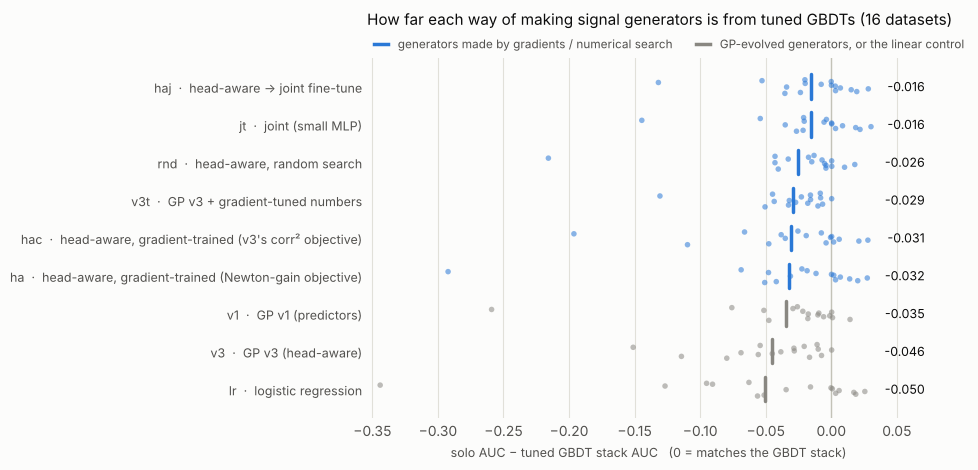

In [6]:
# Gap to the tuned GBDT stack, per method: one dot per dataset, the bar is the mean
# (the number at the right). Left of 0 = worse than tuned GBDTs.
# Emphasis encoding: the generators built by gradients / numerical search in the accent hue;
# GP and the linear control in gray.
ACCENT, GRAY, INK, MUTED, GRID = "#2a78d6", "#898781", "#0b0b0b", "#52514e", "#e1e0d9"
order = (mean[M].sub(mean["g"], axis=0)).mean().sort_values().index.tolist()
grad = {"v3t", "hac", "ha", "jt", "haj", "rnd"}
gaps = mean[M].sub(mean["g"], axis=0)
lo, hi = float(gaps.min().min()), float(gaps.max().max())
xr = (lo - 0.01, max(hi, 0.0) + 0.045)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
fig.patch.set_facecolor("#fcfcfb"); ax.set_facecolor("#fcfcfb")
for i, m in enumerate(order):
    d = gaps[m]
    c = ACCENT if m in grad else GRAY
    ax.scatter(d, np.full(len(d), i) + np.linspace(-0.18, 0.18, len(d)), s=16, color=c, alpha=0.55,
               edgecolor="none", zorder=3)
    ax.plot([d.mean(), d.mean()], [i - 0.32, i + 0.32], color=c, lw=2.5, solid_capstyle="round", zorder=4)
    ax.text(xr[1] - 0.004, i, f"{d.mean():+.3f}", va="center", ha="right", color=INK, fontsize=9)
ax.axvline(0, color="#c3c2b7", lw=1, zorder=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{m}  ·  {LABELS[m]}" for m in order], fontsize=9, color=INK)
ax.set_xlim(*xr)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=ACCENT, lw=2.5, label="generators made by gradients / numerical search"),
                   Line2D([], [], color=GRAY, lw=2.5, label="GP-evolved generators, or the linear control")],
          loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2, frameon=False, fontsize=8.5,
          labelcolor=MUTED, handlelength=1.2, borderaxespad=0.2)
ax.set_xlabel("solo AUC − tuned GBDT stack AUC   (0 = matches the GBDT stack)", color=MUTED, fontsize=9)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(colors=MUTED, length=0)
ax.set_title("How far each way of making signal generators is from tuned GBDTs (16 datasets)",
             loc="left", fontsize=11, color=INK, pad=24)
plt.tight_layout(); plt.show()

### 4.2 · As a fourth expert in the tuned GBDT stack

This is the investigation's real test: does the model add signal that a tuned GBDT stack lacks? It is added as a fourth input to the stack's leakage-free logistic meta-learner. For reference, the investigation measured +0.002 (v1) and ≈0 (v3) here.

In [7]:
sig = {}
for m in M:
    w, l = wins(rows, "g+" + m, "g")
    sig[m] = (w, l)
st = pd.DataFrame(dict(
    mean_delta=stackd.mean(), median_delta=stackd.median(),
    p_xds=[xds_wilcoxon([r["mean"]["g+" + m] for r in rows], [r["mean"]["g"] for r in rows]) for m in M],
    helps=[f"{sig[m][0]}/{len(rows)}" for m in M], hurts=[f"{sig[m][1]}/{len(rows)}" for m in M]),
    index=M)
st["p_xds"] = st["p_xds"].map(fmt_p)
print("Adding each model as a 4th input to the tuned GBDT stack (ΔAUC vs the stack alone):")
print(st.round(4).to_string())
print("\nhelps / hurts = datasets where the gain / loss is significant at fold level (paired Wilcoxon, p<0.05)")
print("\nper dataset:")
print(stackd.round(4).to_string())

Adding each model as a 4th input to the tuned GBDT stack (ΔAUC vs the stack alone):
     mean_delta  median_delta   p_xds  helps hurts
lr       0.0049        0.0005  0.0577   8/16  0/16
v1       0.0021        0.0009  0.0934   8/16  3/16
v3      -0.0015       -0.0003  0.2522   2/16  3/16
v3t      0.0012        0.0003  0.1591   1/16  0/16
hac      0.0052        0.0023  0.0155   8/16  1/16
ha       0.0045        0.0008  0.0443   8/16  1/16
jt       0.0065        0.0032  0.0021  11/16  0/16
haj      0.0061        0.0049  0.0017  10/16  1/16
rnd      0.0032        0.0019  0.0155   6/16  0/16

helps / hurts = datasets where the gain / loss is significant at fold level (paired Wilcoxon, p<0.05)

per dataset:
                       lr      v1      v3     v3t     hac      ha      jt     haj     rnd
sonar              0.0006 -0.0047 -0.0076  0.0064  0.0048  0.0014  0.0111  0.0102  0.0066
ionosphere         0.0050  0.0132  0.0077  0.0069  0.0104  0.0074  0.0120  0.0088  0.0102
kc2                

**Reading it.**
- **The gradient-trained models add real complementary signal.** `jt` adds +0.0065 on average (median +0.003), significant across datasets (p = 0.002). At fold level it helps significantly on 11 of 16 datasets and hurts on none. `haj` is similar (+0.006, p = 0.002). That is three times v1's +0.002, the best GP variant in the investigation (reproduced here). v3 again adds nothing (−0.0015).
- **It is a small-data effect:** +0.010 on the 10 small datasets, +0.001 on the 6 large ones.
- **Most of it is what any smooth model adds.** Plain logistic regression adds +0.005 (+0.008 on small data; p = 0.06 across datasets; significant on 8 datasets, hurts on none). Stacking the MLP instead of the LR gains only +0.0015 more (11/16, p = 0.06). So the complementary signal is mostly smooth or linear structure that depth-4 trees approximate in steps, not something specific to signal generators.

### 4.3 · Which ingredient does the work?

Paired comparisons isolate each step from GP to MLP: tuning GP's numbers, replacing GP's search, fixing the objective, keeping or dropping head-aware greedy growth.

In [8]:
pairs = [("v3t", "v3", "tune v3's numbers by gradient"),
         ("rnd", "v3", "random search vs GP evolution (same head-aware idea)"),
         ("hac", "v3", "gradient ascent on v3's exact objective vs GP"),
         ("ha", "hac", "Newton-gain objective vs v3's corr²"),
         ("ha", "v3", "gradient head-aware (fixed objective) vs GP"),
         ("haj", "ha", "+ joint fine-tune after greedy growth"),
         ("jt", "ha", "joint training vs greedy head-aware"),
         ("jt", "haj", "joint from scratch vs greedy→joint"),
         ("jt", "lr", "small MLP vs logistic regression"),
         ("jt", "g", "small MLP vs tuned GBDT stack")]
out = []
for a, b, what in pairs:
    d = mean[a] - mean[b]
    out.append(dict(comparison=f"{a} vs {b}", question=what, mean_delta=d.mean(), median_delta=d.median(),
                    a_better=f"{int((d > 0).sum())}/{len(d)}", p_xds=fmt_p(xds_wilcoxon(mean[a], mean[b]))))
print(pd.DataFrame(out).set_index("comparison").round(4).to_string())

                                                        question  mean_delta  median_delta a_better    p_xds
comparison                                                                                                  
v3t vs v3                          tune v3's numbers by gradient      0.0164        0.0079    16/16  <0.0001
rnd vs v3   random search vs GP evolution (same head-aware idea)      0.0198        0.0096    12/16   0.0386
hac vs v3          gradient ascent on v3's exact objective vs GP      0.0148        0.0017     9/16   0.5282
ha vs hac                    Newton-gain objective vs v3's corr²     -0.0012        0.0012     9/16   0.7057
ha vs v3             gradient head-aware (fixed objective) vs GP      0.0136        0.0048     9/16   0.3484
haj vs ha                  + joint fine-tune after greedy growth      0.0164        0.0017    13/16   0.0052
jt vs ha                     joint training vs greedy head-aware      0.0164        0.0037    14/16   0.0021
jt vs haj          

**Reading it: which ingredient does the work?**
1. **Gradient-tuning GP's numbers helps on every dataset** (+0.016, 16/16, p < 10⁻⁴). GP is poor at fitting continuous constants, which is why gradient-based constant fitting is standard in modern symbolic regression (Kommenda et al., 2020). It is the least invasive change (v3's evolved structure is kept), but the relaxed comparisons make inference slower (§4.4).
2. **GP is the weak link, not the head-aware objective.** Random search over ridge units on the same objective beats GP evolution over expression trees (+0.020, p = 0.04). This pair differs in function class as well as search, so it implicates GP's search, its function class, or both.
3. **Gradient ascent on the head-aware objective alone is not enough.** `hac` and `ha` gain only +0.014–0.015 over v3, not significant. Growing frozen units greedily, one at a time, is a weak training scheme; that is the long-standing lesson of cascade-correlation and constructive networks. The Newton-gain fix does rescue the many-features, few-rows case (sonar: 0.768 → 0.827), but on average `hac` ≈ `ha`. The two arms also differ in regularization (α = 10 vs 30, each chosen on dev), so this pair isn't a clean ablation of the objective; §3.1 is.
4. **Joint training is what works.** `jt` beats greedy head-aware by +0.016 (14/16, p = 0.002). Initializing the joint training from head-aware growth adds nothing (`jt` − `haj` = 0.000, p = 0.71).

So the honest reading of the original idea: "signal generators feeding a linear head" *is* a hidden layer, and the way to get good hidden units is to train them jointly, not greedily against the head's residual.

### 4.4 · The artifact: do trained generators keep the nanosecond C?

Each model is fitted on fold 0, compiled to a dependency-free `.so`, and timed inside C on 16 different input rows on an idle machine, as in the investigation's addendum. *Spread* and *CoV* are the input-dependent jitter. Ridge generators compile to a small matrix–vector product plus vectorized `tanhf` (glibc libmvec): branchless, like GP. The reference compiled tree model is the benchmark's tuned XGBoost, compiled with XGForge.

In [9]:
L = json.load(open(os.path.join(root, "benchmarks/results/gradgen_latency.json")))
lat = pd.DataFrame(L["models"]).fillna("")
lat["size"] = [f"{int(g)} gens" if g != "" else (f"{int(n)} nodes" if n != "" else f"{int(t)} trees")
               for g, n, t in zip(lat["generators"], lat["nodes"], lat["trees"])]
cols = ["dataset", "d", "model", "size", "kb", "ns_mean", "cov_pct", "noise_cov_pct", "auc_py", "auc_c"]
print(lat[cols].rename(columns={"kb": "KB", "ns_mean": "ns/row", "cov_pct": "CoV% (16 inputs)",
                                "noise_cov_pct": "CoV% (same input)"}).to_string(index=False))
print("\nvectorized tanhf vs input magnitude (spambase jt; median of 5 passes per row):")
print(pd.DataFrame(L["tanh_input_magnitude"]).to_string(index=False))

 dataset  d                     model      size    KB  ns/row  CoV% (16 inputs)  CoV% (same input)  auc_py  auc_c
diabetes  8        v3 (GP head-aware) 578 nodes  15.4    72.8             17.67               6.06  0.7878 0.7878
diabetes  8  v3t (GP + tuned numbers) 578 nodes  19.4   347.7             13.43               4.51  0.7924 0.7924
diabetes  8 ha (head-aware, gradient)    4 gens  15.4    25.4              3.06               2.20  0.8343 0.8343
diabetes  8    jt (joint / small MLP)   24 gens  15.4    68.3             42.13               3.33  0.8356 0.8356
diabetes  8   XGBoost tuned (XGForge)  27 trees  31.4    33.7              6.08               1.29  0.8161 0.8161
   magic 10        v3 (GP head-aware) 217 nodes  15.4    36.9              8.63              15.50  0.9038 0.9038
   magic 10  v3t (GP + tuned numbers) 217 nodes  15.4    83.3              5.65              20.78  0.9078 0.9078
   magic 10 ha (head-aware, gradient)   16 gens  15.4    65.8             16.62         

**Reading it.**
- **Every trained model still compiles to a dependency-free ~15–20 KB `.so` with sub-µs single-row inference.** C agrees with Python to the fourth decimal of AUC everywhere. A ridge model's cost is a K×d matrix–vector product plus K `tanhf`, so it grows with the feature count: ~25–70 ns on the 8–10-feature sets, ~110–215 ns on spambase's 57. It is also sensitive to code generation (on spambase, `ha`'s 11 units ran slower than `jt`'s 20). GP's cost grows with tree size instead (~40–70 ns here). The tuned XGBoost is 31–149 KB: ~35 ns on diabetes (27 trees) and ~1.2 µs on magic and spambase (~260–290 trees) in single-row C.
- **`v3t` is the slowest** (80–350 ns): each relaxed `<` costs an `expf`. Snapping the comparisons back to hard `<` after tuning would recover GP's speed, at some accuracy cost that isn't measured here.
- **Jitter can't be resolved on this machine.** Timing the *same* input 16 times varies by up to ~30% (CoV) in this cloud VM, about as much as the spread across different inputs. The table shows single-run means; in repeated runs on this VM they moved by up to ~25%. These measurements can't confirm or refute the investigation's latency-determinism contrast. Structurally, the ridge C is as branchless as GP's, and the vectorized `tanhf` costs the same whatever the input magnitude (last table: pre-activations from ~1 to ~90).

## 5 · Conclusion

**Has it been tried?** Yes. Gradient-trained head-aware generators are Cascade-Correlation and constructive networks (1990–97). The orthogonalized objective is orthogonal gradient boosting (2024). Random-candidate selection is Stochastic Configuration Networks (2017). Gradient-fitted GP constants are standard in modern symbolic regression (2020).

**Does it get better results?** Relative to GP, yes:
- v3 with gradient-tuned numbers: +0.016 AUC, on every dataset.
- A jointly trained small MLP with the same 24/20 generators and the same logistic head: +0.030 AUC (13/16, p = 0.003), and about 100× faster to train.
- Even random search over ridge units on the head-aware objective beats GP evolution.

**Does it change the investigation's verdict?** No, it sharpens it.
- **Solo**, the best trained generators match the tuned GBDT stack on the 10 small datasets (where plain logistic regression also does well) and still trail it by ~0.04 AUC on the 6 large ones.
- **Stacked**, they add +0.006 AUC, the largest complementary signal measured in this project and significant across datasets. But most of it is available from plain logistic regression (+0.005), and it is a small-data effect (+0.010 small, +0.001 large).
- **The head-aware idea does not survive gradients.** Training generators jointly beats growing them against the head's residual, and head-aware initialization adds nothing. "Signal generators + linear head" turns out to be a hidden layer, and hidden layers are best trained jointly.

**So the recommendation stays the investigation's, with one refinement.** For tabular classification, use a tuned GBDT (or TabPFN on small data). If you want a tiny, dependency-free C model anyway, a small jointly trained MLP is a better choice than an evolved GP ensemble: similar artifact size and latency, better accuracy, and about 100× faster to train. Blending one (or just a logistic regression) into a GBDT stack is a cheap way to pick up a little AUC on small datasets.

**Limitations (where this could be wrong).**
- One generator family (tanh ridge units) and one budget (24/20 units, matched to v3's head width). On dev data a 128-unit MLP was no better, but richer tabular deep-learning machinery (feature embeddings, ensembling, e.g. TabM or RealMLP) was out of scope.
- `ha` and `hac` differ in regularization as well as objective, so they don't isolate the Newton-gain fix on the benchmark. The clean demonstration is §3.1.
- 16 datasets of at most 6,000 rows. Cross-dataset tests have limited power: `jt` vs GBDT at p = 0.21 means "not shown to differ", not "equal".
- Latency jitter couldn't be resolved in this VM; means and sizes are reported.

## 6 · Reproducibility & references

**Reproduce:** `pip install -e ".[benchmark]"`, then from the repo root:
- `PYTHONPATH=. python3 benchmarks/gradgen_dev.py` and `... gradgen_dev.py report`: the dev-set selection (14 datasets, every config tried, `results/gradgen_dev.jsonl`)
- `PYTHONPATH=. python3 benchmarks/gradgen_vs_gp.py`: this benchmark (resumable; ~4 CPU-hours; per-fold rows in `results/gradgen_vs_gp_folds.jsonl`)
- `PYTHONPATH=. python3 benchmarks/gradgen_latency.py`: §4.4 (run on an idle machine)
- `PYTHONPATH=. python3 tests/test_gradgen.py`: gradient checks and C↔Python agreement

### References
- Fahlman, S. & Lebiere, C. (1990). The Cascade-Correlation learning architecture. *Advances in NeurIPS 2.* [paper](https://proceedings.neurips.cc/paper/1989/file/69adc1e107f7f7d035d7baf04342e1ca-Paper.pdf)
- Kwok, T.-Y. & Yeung, D.-Y. (1997). Objective functions for training new hidden units in constructive neural networks. *IEEE Trans. Neural Networks* 8, 1131–1148. [doi:10.1109/72.623214](https://doi.org/10.1109/72.623214)
- Friedman, J. & Stuetzle, W. (1981). Projection pursuit regression. *JASA* 76, 817–823.
- Friedman, J. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics* 29.
- Wang, D. & Li, M. (2017). Stochastic Configuration Networks: fundamentals and algorithms. *IEEE Trans. Cybernetics* 47. [arXiv:1702.03180](https://arxiv.org/abs/1702.03180)
- Badirli, S. et al. (2020). Gradient boosting neural networks: GrowNet. [arXiv:2002.07971](https://arxiv.org/abs/2002.07971)
- Kommenda, M., Burlacu, B., Kronberger, G. & Affenzeller, M. (2020). Parameter identification for symbolic regression using nonlinear least squares. *GPEM* 21, 471–501. [doi:10.1007/s10710-019-09371-3](https://doi.org/10.1007/s10710-019-09371-3)
- Yang, F., Le Bodic, P., Kamp, M. & Boley, M. (2024). Orthogonal gradient boosting for simpler additive rule ensembles. *AISTATS*, PMLR 238. [link](https://proceedings.mlr.press/v238/yang24b.html)
- Chen, T. & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD.*
- Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *JMLR* 7, 1–30.
- Grinsztajn, L., Oyallon, E. & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on tabular data? *NeurIPS Datasets & Benchmarks.*

In [10]:
import sklearn, scipy, xgboost, lightgbm, platform
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn",
      sklearn.__version__, "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__)
print(platform.processor() or platform.machine(), "|", os.cpu_count(), "cores")

python 3.13.16 | numpy 2.5.3 | scipy 1.18.1 | sklearn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0
x86_64 | 4 cores
